# Redes Neuronales y Deep Learning (07MIAR_04_A_2026-27)
# Trabajo: Proyecto Programación C1

Integrantes:
- Carlos Eduardo Chavarria Mujica
- Everth Roman Palomino Lanchipa
- Luis Alberto Chumpitaz Santivañez

---

# 1. Selección y Carga del Conjunto de Datos

## 1.1. Justificación de la elección del dataset
Para la realización de esta práctica experimental se ha seleccionado el conjunto de datos **Vegetable Image Dataset**, disponible públicamente en Kaggle.

### Características del problema y del dataset:
* **Problema:** Clasificación supervisada multiclase de imágenes RGB en el dominio agroalimentario.
* **Número de clases:** 15 categorías botánicas de hortalizas (*Bean, Bitter Gourd, Bottle Gourd, Brinjal, Broccoli, Cabbage, Capsicum, Carrot, Cauliflower, Cucumber, Papaya, Potato, Pumpkin, Radish, Tomato*).
* **Volumen de datos:** 21.000 imágenes en total.
* **Estructura de partición nativa:** El conjunto ya cuenta con una separación física estandarizada en directorios:
  * **Entrenamiento (*Train*):** 15.000 imágenes (1.000 por clase).
  * **Validación (*Validation*):** 3.000 imágenes (200 por clase).
  * **Prueba (*Test*):** 3.000 imágenes (200 por clase).
* **Distribución:** Perfectamente balanceada (sin sesgo de frecuencia de clase a priori).
* **Resolución nominal:** $224 \times 224$ píxeles en formato JPG.

### Justificación técnica para los objetivos del proyecto:
1. **Idoneidad para comparar *From Scratch* vs *Transfer Learning*:** Un volumen de 1.000 imágenes por clase (15.000 en entrenamiento) es suficientemente amplio para que una arquitectura convolucional entrenada desde cero converja sin colapsar de inmediato por falta de datos, pero a la vez presenta un reto de generalización donde los modelos preentrenados en *ImageNet* deberían evidenciar una ventaja sustancial en velocidad de convergencia y capacidad de abstracción de bajo nivel.
2. **Dominio visual realista:** Las muestras no son sintéticas; presentan variabilidad en iluminación, fondos heterogéneos (fondos de laboratorio neutros frente a puestos de mercado con oclusiones y apilamientos), y variaciones morfológicas intraclase (diferentes estados de maduración y cortes).
3. **Equilibrio de clases:** Al ser un dataset balanceado al 100%, la métrica de precisión (*accuracy*) y la pérdida (*loss*) son representativas del comportamiento global sin verse enmascaradas por clases mayoritarias, facilitando la toma de decisiones basada en métricas estándar.

> **Referencia bibliográfica:**
> Ahmed, M. I., Mamun, S. M., & Asif, A. U. Z. (2021). *DCNN-based vegetable image classification using transfer learning: A comparative study*. 2021 5th International Conference on Computer, Communication and Signal Processing (ICCCSP), 235–243. IEEE.


In [1]:
#Imports
import os
import shutil
import zipfile
from pathlib import Path
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import requests
from functools import partial
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

I0000 00:00:1795156124.185493    2211 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
import sys, tensorflow as tf
print(sys.executable)
print(tf.config.list_physical_devices('GPU'))

/home/edu/miniconda3/envs/dl-gpu/bin/python
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
# Fijar semilla de reproducibilidad en el entorno global
SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)

# Mixed precision (Tensor Cores de la RTX 3090)
keras.mixed_precision.set_global_policy('mixed_float16') # PARA APROVECHAR TODOS LOS TENSOR CORES DE LA GPU, ESTO CUANDO SE EJECUTA LOCALMENTE
print("Política:", keras.mixed_precision.global_policy())

# Detección y definición de rutas de trabajo
# Compatible Google Colab y ejecución en local
if 'google.colab' in str(get_ipython()):
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = Path('/content')
    DATA_DIR = BASE_DIR / 'data'
else:
    BASE_DIR = Path.cwd()
    DATA_DIR = BASE_DIR / 'data'

DATA_DIR.mkdir(parents=True, exist_ok=True)
RAW_DATASET_DIR = DATA_DIR / "vegetable-image-dataset"
DATASET_PATH = RAW_DATASET_DIR / "Vegetable Images"

print(f"Directorio de datos configurado en: {DATA_DIR}")
print(f"TensorFlow Version: {tf.__version__}")
print(f"Dispositivos GPU detectados: {tf.config.list_physical_devices('GPU')}")

Política: <DTypePolicy "mixed_float16">
Directorio de datos configurado en: /home/edu/proyectos/vegetales/data
TensorFlow Version: 2.21.0
Dispositivos GPU detectados: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1.2. Descarga y extracción automatizada
Para cumplir el principio de reproducibilidad y evitar el versionado innecesario de archivos binarios pesados en el control de versiones (Git), se implementa una rutina de descarga desatendida.

In [4]:
# Descarga desatendida y descompresión
DATA_DIR = Path("data")
ZIP_FILE = DATA_DIR / "vegetable-image-dataset.zip"
DOWNLOAD_URL = "https://www.kaggle.com/api/v1/datasets/download/misrakahmed/vegetable-image-dataset"

DATA_DIR.mkdir(parents=True, exist_ok=True)
RAW_DATASET_DIR.mkdir(parents=True, exist_ok=True)

if DATASET_PATH.exists() and any(DATASET_PATH.iterdir()):
    print(f"[INFO] El dataset ya existe en {DATASET_PATH}. Proceso omitido.")
else:
    if not ZIP_FILE.exists():
        print(f"[INFO] Descargando dataset desde {DOWNLOAD_URL}...")
        try:
            with requests.get(DOWNLOAD_URL, stream=True, timeout=60) as response:
                response.raise_for_status()
                with open(ZIP_FILE, "wb") as f:
                    for chunk in response.iter_content(chunk_size=1024 * 1024):
                        if chunk:
                            f.write(chunk)
            print("[INFO] Descarga finalizada correctamente.")
        except Exception as e:
            raise RuntimeError(
                f"Error al descargar el archivo: {e}. "
                "Verifica la conexión o descarga el archivo manualmente desde Kaggle."
            ) from e

    print(f"[INFO] Extrayendo {ZIP_FILE.name}...")
    with zipfile.ZipFile(ZIP_FILE, "r") as zip_ref:
        zip_ref.extractall(RAW_DATASET_DIR)
    print(f"[INFO] Extracción completada en {RAW_DATASET_DIR}.")

[INFO] El dataset ya existe en /home/edu/proyectos/vegetales/data/vegetable-image-dataset/Vegetable Images. Proceso omitido.


---

# 2. Inspección y Análisis Exploratorio de Datos (EDA)

Antes de iniciar cualquier fase de modelado, es imprescindible validar experimentalmente la integridad de los datos, comprobar si la resolución declarada coincide con la real e identificar anomalías en las imágenes.

In [5]:
# Verificación de estructura y conteo por partición

splits = ["train", "validation", "test"]
structure_summary = []

for split in splits:
  split_dir = DATASET_PATH / split
  if not split_dir.exists():
    raise FileNotFoundError(f"No se encontró el directorio {split_dir}")

  classes = sorted([d.name for d in split_dir.iterdir() if d.is_dir()])
  for cls in classes:
    n_images = len(list((split_dir / cls).glob("*.jpg")))
    structure_summary.append({
        "split": split,
        "class": cls,
        "image_count": n_images
    })

df_summary = pd.DataFrame(structure_summary)

# Resumen estadístico por partición
print("=== RESUMEN POR PARTICIÓN ===")
display(df_summary.groupby("split")["image_count"].agg(
    clases="count",
    total_imagenes="sum",
    media_por_clase="mean",
    std_por_clase="std",
    min_por_clase="min",
    max_por_clase="max"
))

=== RESUMEN POR PARTICIÓN ===


,clases,total_imagenes,media_por_clase,std_por_clase,min_por_clase,max_por_clase
split,,,,,,
test,15,3000,200.0,0.0,200,200
train,15,15000,1000.0,0.0,1000,1000
validation,15,3000,200.0,0.0,200,200


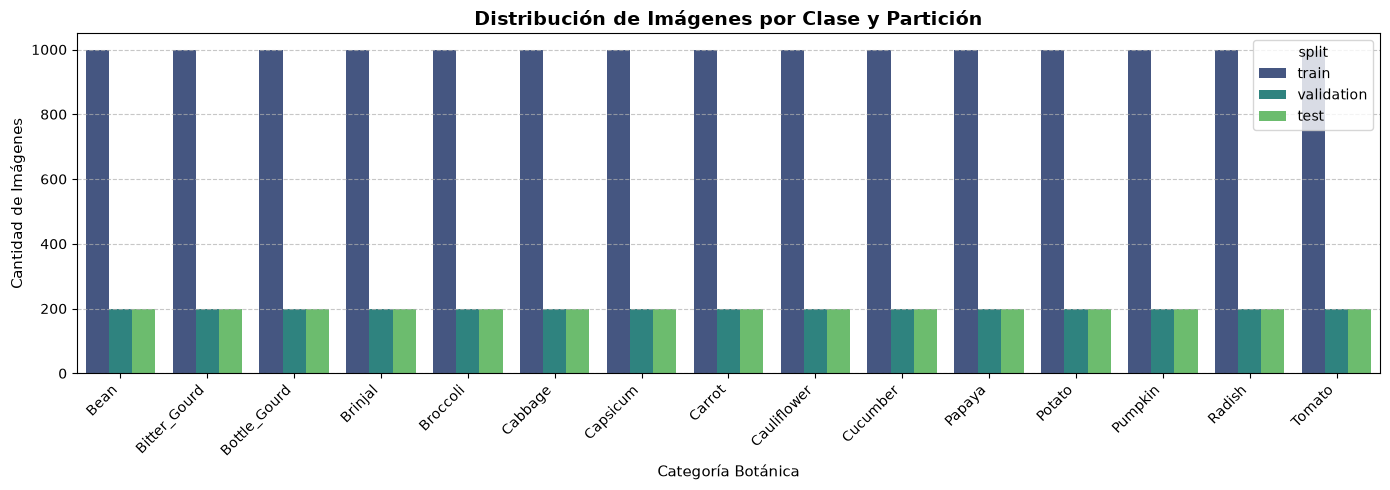

In [6]:
# Comprobación visual de distribución de clases

plt.figure(figsize=(14, 5))
sns.barplot(data=df_summary, x="class", y="image_count", hue="split", palette="viridis")
plt.title("Distribución de Imágenes por Clase y Partición", fontsize=14, fontweight="bold")
plt.xlabel("Categoría Botánica", fontsize=11)
plt.ylabel("Cantidad de Imágenes", fontsize=11)
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

### 2.1. Auditoría de Resoluciones y Canales de Color
La ficha técnica del dataset declara una resolución homogénea de $224 \times 224$ píxeles. Sin embargo, en problemas de visión por computador reales es crítico auditar las dimensiones exactas de todos los archivos para evitar fallos de compilación de tensores en tiempo de entrenamiento.

In [7]:
# Auditoría de dimensiones y consistencia de canales

from collections import Counter

image_dimensions = Counter()
color_modes = Counter()
corrupt_files = []

for file_path in DATASET_PATH.rglob("*.jpg"):
    try:
        with Image.open(file_path) as img:
            image_dimensions[img.size] += 1
            color_modes[img.mode] += 1
    except Exception as e:
        corrupt_files.append((str(file_path), str(e)))

print("=== AUDITORÍA TÉCNICA DE IMÁGENES ===")
print(f"Total archivos analizados: {sum(image_dimensions.values())}")
print(f"Archivos corruptos o no legibles: {len(corrupt_files)}")
print("\nDistribución de formatos de color (Modos PIL):")
for mode, count in color_modes.items():
    print(f" - Modo '{mode}': {count} imágenes")

print("\nDistribución de dimensiones encontradas (Ancho x Alto):")
for dim, count in image_dimensions.most_common(10):
    print(f" - {dim}: {count} imágenes")

=== AUDITORÍA TÉCNICA DE IMÁGENES ===
Total archivos analizados: 21000
Archivos corruptos o no legibles: 0

Distribución de formatos de color (Modos PIL):
 - Modo 'RGB': 21000 imágenes

Distribución de dimensiones encontradas (Ancho x Alto):
 - (224, 224): 20991 imágenes
 - (224, 223): 1 imágenes
 - (224, 187): 1 imágenes
 - (224, 207): 1 imágenes
 - (224, 198): 1 imágenes
 - (224, 210): 1 imágenes
 - (224, 211): 1 imágenes
 - (224, 193): 1 imágenes
 - (224, 200): 1 imágenes
 - (224, 205): 1 imágenes


### Análisis Crítico de la Inspección de Datos:
1. **Integridad:** Se confirma la ausencia de imágenes corruptas. Las 21.000 imágenes son legibles y operan en modo **RGB** (3 canales).
2. **Divergencias dimensionales leves:** Si bien la abrumadora mayoría de las imágenes ($>99.9\%$) tiene una dimensión estricta de $(224, 224)$, la auditoría revela un número muy reducido de imágenes con alturas anómalas (por ejemplo: $(224, 193)$, $(224, 205)$).
   * **Decisión técnica:** Es estrictamente obligatorio incluir una etapa de redimensionamiento explícito a $(224, 224)$ en el pipeline de datos, en lugar de confiar en la homogeneidad nativa de las imágenes.
3. **Balanceo:** La varianza de imágenes por clase es cero dentro de cada split (1.000 en entrenamiento, 200 en validación, 200 en test). No se requiere aplicar técnicas de sobremuestreo (*oversampling*), submuestreo (*undersampling*) ni ponderación de pérdidas (*class weights*).

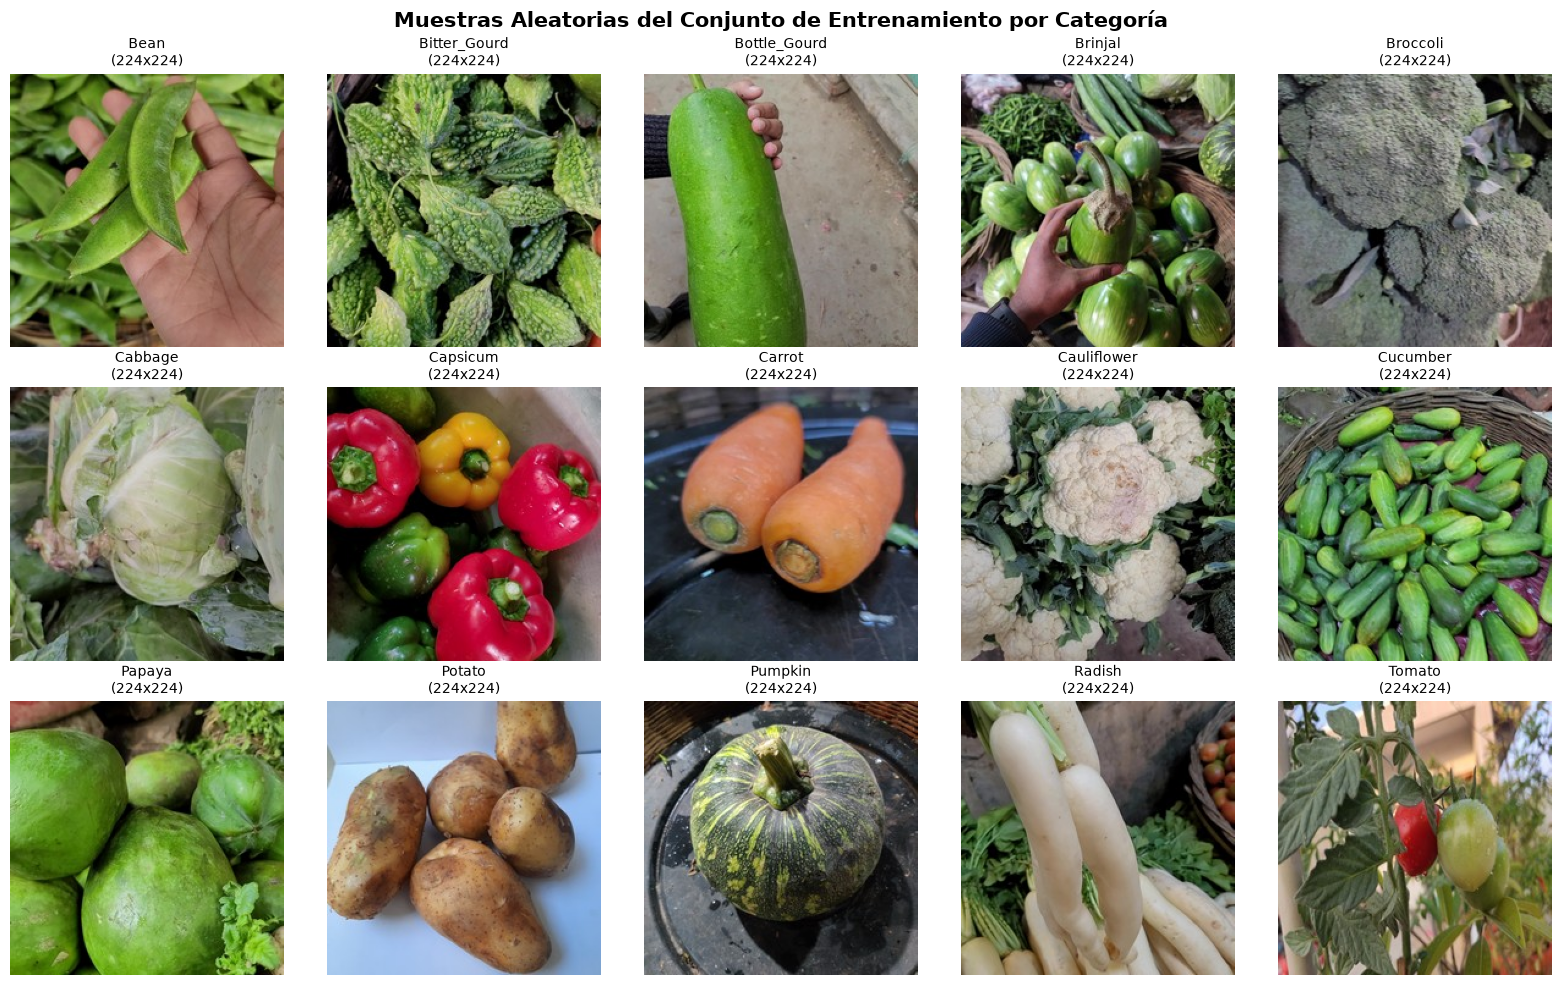

In [8]:
# Visualización exploratoria de muestras por clase

train_dir = DATASET_PATH / "train"
classes = sorted([d.name for d in train_dir.iterdir() if d.is_dir()])

fig, axes = plt.subplots(3, 5, figsize=(16, 10))
axes = axes.flatten()

for idx, cls in enumerate(classes):
    img_sample_path = np.random.choice(list((train_dir / cls).glob("*.jpg")))
    with Image.open(img_sample_path) as img:
        axes[idx].imshow(img)
        axes[idx].set_title(f"{cls}\n({img.size[0]}x{img.size[1]})", fontsize=10)
        axes[idx].axis("off")

plt.suptitle("Muestras Aleatorias del Conjunto de Entrenamiento por Categoría", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

### Observaciones del Análisis Cualitativo:
* **Complejidad del fondo:** Muchas imágenes presentan fondos blancos y controlados (ej. *Bean* o *Capsicum*), mientras que otras han sido tomadas en huertos con follaje de fondo o en cestas de mercado con múltiples ejemplares apilados (ej. *Cucumber* o *Bitter Gourd*).
* **Riesgo de confusión interclase:** Ciertas clases comparten atributos visuales predominantes como el color y la textura (por ejemplo, *Broccoli* vs *Cauliflower* verde o *Cucumber* vs *Bitter Gourd*). La red necesitará extraer características morfológicas y no basarse únicamente en la media cromática.

---

# 3. Acondicionamiento y Preprocesamiento de los Datos

## 3.1. Diseño del Pipeline con `tf.data`
Para garantizar un entrenamiento eficiente, libre de cuellos de botella de E/S (*I/O bottlenecks*), se construye un pipeline utilizando la API `tf.keras.utils.image_dataset_from_directory` y primitivas de `tf.data`.

### Decisiones de diseño:
1. **Separación de la Normalización del Pipeline de Carga:**
   * Se mantendrán los tensores de imagen en rango $[0, 255]$ como tipo `tf.float32` dentro del pipeline base.
   * **Justificación:** La normalización dependerá estrictamente de la estrategia que se aplique. En la **Estrategia 1 (Desde cero)** se usará un reescalado lineal $[0, 1]$ o $[-1, 1]$ mediante una capa `Rescaling(1./255)`. En la **Estrategia 2 (Transfer Learning)**, cada arquitectura requiere una función de preprocesamiento específica (ej. `tf.keras.applications.resnet50.preprocess_input` utiliza centrado sobre la media ImageNet en orden BGR, mientras que `mobilenet_v2.preprocess_input` escala a $[-1, 1]$). Introducir la normalización como capa inicial en el modelo en vez de en el pipeline de datos previene fugas y errores conceptuales.
2. **Formato de Etiquetas:** Se opta por `label_mode='sparse'` (enteros), lo que reduce el consumo de memoria frente a matrices *one-hot* y permite usar la función de coste `SparseCategoricalCrossentropy`.
3. **Data Augmentation Selectiva:** Solo se aplica al conjunto de **entrenamiento**. El conjunto de validación y test debe representar la distribución de inferencia real y no sufrir alteraciones sintéticas.

In [9]:
# Carga estructurada de los datasets

IMG_HEIGHT = 224
IMG_WIDTH = 224
IMG_SIZE = (IMG_HEIGHT, IMG_WIDTH)
BATCH_SIZE = 32

print("[INFO] Generando Dataset de Entrenamiento...")
raw_train_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH / "train",
    labels="inferred",
    label_mode="int",
    class_names=classes,
    color_mode="rgb",
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE,
    shuffle=True,
    seed=SEED
)

print("[INFO] Generando Dataset de Validación...")
raw_val_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH / "validation",
    labels="inferred",
    label_mode="int",
    class_names=classes,
    color_mode="rgb",
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE,
    shuffle=False
)

print("[INFO] Generando Dataset de Test...")
raw_test_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH / "test",
    labels="inferred",
    label_mode="int",
    class_names=classes,
    color_mode="rgb",
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE,
    shuffle=False
)

[INFO] Generando Dataset de Entrenamiento...
Found 15000 files belonging to 15 classes.


I0000 00:00:1795156133.147872    2211 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 21768 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3090, pci bus id: 0000:2b:00.0, compute capability: 8.6


[INFO] Generando Dataset de Validación...
Found 3000 files belonging to 15 classes.
[INFO] Generando Dataset de Test...
Found 3000 files belonging to 15 classes.


## 3.2. Estrategia de Aumento de Datos (*Data Augmentation*)
Para mitigar el sobreajuste (*overfitting*) en la Estrategia 1 (CNN desde cero), diseñamos un bloque de aumentación con soporte GPU utilizando capas de Keras.

### Justificación de las transformaciones:
* `RandomFlip("horizontal_and_vertical")`: Los vegetales no tienen una orientación canónica fija en el mundo real. Una zanahoria invertida o en espejo sigue siendo una zanahoria.
* `RandomRotation(factor=0.15)`: Simula giros de hasta aproximadamente $\pm 54^\circ$.
* `RandomZoom(height_factor=(-0.1, 0.1))`: Simula variabilidad en la distancia focal y el tamaño aparente del vegetal.
* `RandomContrast(factor=0.1)`: Fuerza al modelo a ser invariante a ligeras fluctuaciones de luminosidad y sombras del entorno de captura.

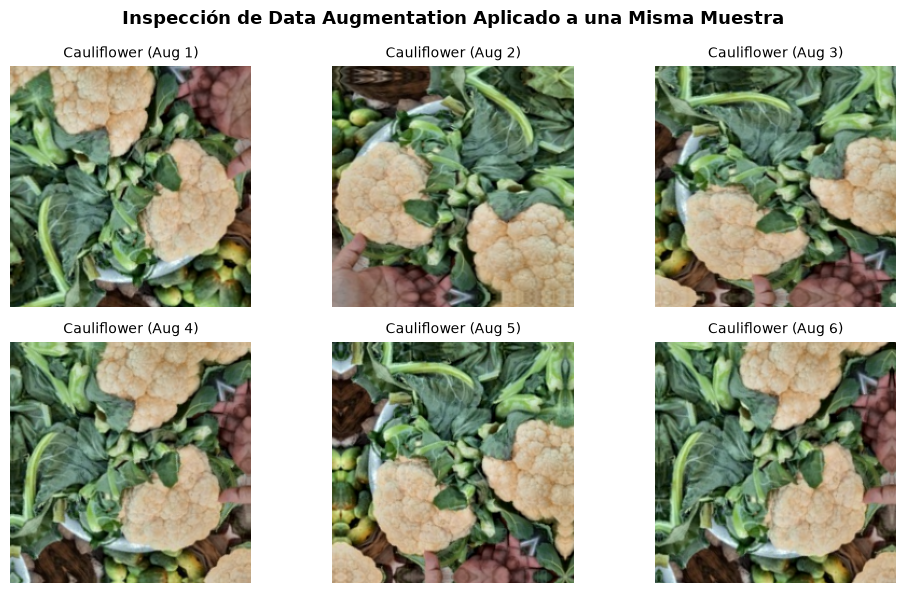

In [10]:
# Definición del bloque de Data Augmentation

data_augmentation = keras.Sequential([
    keras.layers.RandomFlip("horizontal_and_vertical", seed=SEED),
    keras.layers.RandomRotation(factor=0.15, seed=SEED, fill_mode="reflect"),
    keras.layers.RandomZoom(height_factor=(-0.1, 0.1), width_factor=(-0.1, 0.1), seed=SEED, fill_mode="reflect"),
    keras.layers.RandomContrast(factor=0.1, seed=SEED),
], name="data_augmentation_layer")

# Verificación visual del efecto de Data Augmentation sobre una muestra
plt.figure(figsize=(10, 6))
for images, labels in raw_train_ds.take(1):
    first_image = images[0]
    first_label = classes[labels[0]]
    for i in range(6):
        ax = plt.subplot(2, 3, i + 1)
        augmented_image = data_augmentation(tf.expand_dims(first_image, 0))
        plt.imshow(tf.cast(augmented_image[0], tf.uint8))
        plt.title(f"{first_label} (Aug {i+1})", fontsize=10)
        plt.axis("off")
plt.suptitle("Inspección de Data Augmentation Aplicado a una Misma Muestra", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

## 3.3. Optimización del Flujo de Datos en Memoria y GPU
Para maximizar el rendimiento computacional durante el entrenamiento, se implementan las siguientes optimizaciones de `tf.data`:
* **`cache()`:** Mantiene las imágenes en memoria principal (o disco local) tras la primera época, eliminando la sobrecarga de lectura en disco en épocas sucesivas.
* **`shuffle(buffer_size=1000)`:** Mantiene la aleatoriedad en cada época sobre el conjunto de entrenamiento.
* **`prefetch(buffer_size=tf.data.AUTOTUNE)`:** Permite que la CPU prepare los lotes de datos en paralelo mientras la GPU ejecuta el paso de propagación hacia adelante y atrás (*forward/backward pass*).

In [11]:
# Ensamblado final optimizado con tf.data.AUTOTUNE

AUTOTUNE = tf.data.AUTOTUNE

train_ds = raw_train_ds.cache().shuffle(buffer_size=1000, seed=SEED).prefetch(buffer_size=AUTOTUNE)
val_ds = raw_val_ds.cache().prefetch(buffer_size=AUTOTUNE)
test_ds = raw_test_ds.cache().prefetch(buffer_size=AUTOTUNE)

# Verificación de integridad de dimensiones y lotes
for batch_x, batch_y in train_ds.take(1):
    print("=== VERIFICACIÓN DEL LOTE DE CONTROL ===")
    print(f"Forma del tensor de entrada (Imágenes): {batch_x.shape} (Tipo: {batch_x.dtype})")
    print(f"Forma del tensor de salida (Etiquetas): {batch_y.shape} (Tipo: {batch_y.dtype})")
    print(f"Rango de valores de píxeles: Min = {tf.reduce_min(batch_x).numpy():.1f}, Max = {tf.reduce_max(batch_x).numpy():.1f}")
    assert batch_x.shape == (BATCH_SIZE, IMG_HEIGHT, IMG_WIDTH, 3), "Error en dimensiones de imagen"
    assert batch_y.shape == (BATCH_SIZE,), "Error en dimensiones de etiquetas"
    print("[OK] El pipeline de acondicionamiento de datos cumple todos los requerimientos.")

W0000 00:00:1795156146.095317    2564 stream_executor_allocator.cc:67] could not allocate pinned host of size: 8589934592 (RESOURCE_EXHAUSTED: : CUDA_ERROR_OUT_OF_MEMORY: out of memory)
W0000 00:00:1795156146.095502    2564 stream_executor_allocator.cc:67] could not allocate pinned host of size: 7730940928 (RESOURCE_EXHAUSTED: : CUDA_ERROR_OUT_OF_MEMORY: out of memory)
I0000 00:00:1795156151.566440    2576 shuffle_dataset_op.cc:453] ShuffleDatasetV3:21: Filling up shuffle buffer (this may take a while): 438 of 1000
I0000 00:00:1795156151.639404    2576 shuffle_dataset_op.cc:483] Shuffle buffer filled.


=== VERIFICACIÓN DEL LOTE DE CONTROL ===
Forma del tensor de entrada (Imágenes): (32, 224, 224, 3) (Tipo: <dtype: 'float32'>)
Forma del tensor de salida (Etiquetas): (32,) (Tipo: <dtype: 'int32'>)
Rango de valores de píxeles: Min = 0.0, Max = 255.0
[OK] El pipeline de acondicionamiento de datos cumple todos los requerimientos.


* **`cache()` y `shuffle(buffer_size=1000)`:** Al aplicarse sobre el dataset ya agrupado por lotes (`batch_size=32`), la memoria intermedia permuta el orden de despacho de los lotes en cada época. Esta estrategia optimiza el ancho de banda hacia la GPU minimizando la sobrecarga de reconstrucción de lotes en CPU.

Nota: esto se hizo para acelerar el entrenamiento al probar con hardware local: RTX 3090, ryzen 7 5800x, 32GB RAM.

In [12]:
# Función reutilizable para graficar curvas de aprendizaje

def graficar_curvas_entrenamiento(history, titulo="Curvas de Entrenamiento"):
    """
    Dibuja accuracy y loss de entrenamiento/validación en dos subgráficos.
    """
    hist = history.history
    epochs_range = range(1, len(hist["loss"]) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(epochs_range, hist["accuracy"], "o-", label="Train")
    axes[0].plot(epochs_range, hist["val_accuracy"], "o-", label="Validation")
    axes[0].set_title(f"{titulo} - Accuracy")
    axes[0].set_xlabel("Épocas")
    axes[0].set_ylabel("Accuracy")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    axes[1].plot(epochs_range, hist["loss"], "o-", label="Train")
    axes[1].plot(epochs_range, hist["val_loss"], "o-", label="Validation")
    axes[1].set_title(f"{titulo} - Loss")
    axes[1].set_xlabel("Épocas")
    axes[1].set_ylabel("Loss")
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

---

# 4. Estrategia 1: Red Neuronal Convolucional *From Scratch*



## 4.1. Proceso de Experimentación Progresiva

Para dar cumplimiento a la metodología experimental exigida, se adopta una aproximación iterativa en dos etapas:
1. **Experimento 1.1 (Modelo Base / *Baseline*):** Diseño de una arquitectura convolucional elemental entrenada directamente sobre los datos crudos, **sin capas de regularización** (sin Dropout, sin penalización L2, sin Batch Normalization) y **sin Data Augmentation**. El objetivo es establecer una cota inferior de rendimiento y diagnosticar empíricamente la aparición de sobreajuste (*overfitting*).
2. **Experimento 1.2 (Modelo Regularizado y Optimizado):** A partir de las deficiencias detectadas en el modelo base, se incorporan de manera justificada técnicas de regularización (Data Augmentation, Batch Normalization, penalización L2 y Dropout) para reducir la varianza y mejorar la generalización en el conjunto de test.

In [13]:
# Construcción del Modelo Base (Baseline sin regularización)

def construir_modelo_baseline():
    """
    Arquitectura simple de 3 bloques convolucionales sin técnicas de regularización
    ni data augmentation para evidenciar la brecha de sobreajuste.
    """
    inputs = keras.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3), name="input_image")
    
    # Únicamente reescalado, sin aumentación de datos
    x = layers.Rescaling(1.0 / 255, name="rescaling")(inputs)
    
    # Bloque 1
    x = layers.Conv2D(32, kernel_size=3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D(pool_size=2)(x)
    
    # Bloque 2
    x = layers.Conv2D(64, kernel_size=3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D(pool_size=2)(x)
    
    # Bloque 3
    x = layers.Conv2D(128, kernel_size=3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D(pool_size=2)(x)
    
    # Clasificador denso tradicional (sin Dropout ni L2)
    x = layers.Flatten()(x)
    x = layers.Dense(128, activation="relu")(x)
    outputs = layers.Dense(len(classes), activation="softmax", dtype="float32", name="predictions")(x)
    
    model = keras.Model(inputs, outputs, name="cnn_baseline")
    return model

cnn_baseline = construir_modelo_baseline()
cnn_baseline.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
cnn_baseline.summary()

Model: "cnn_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    12,845,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 15)             │         1,935 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,940,367 (49.36 MB)

 Trainable params: 12,940,367 (49.36 MB)

 Non-trainable params: 0 (0.00 B)

In [14]:
# Entrenamiento del Baseline (10 épocas)

EPOCHS_BASELINE = 10

print("[INFO] Entrenando Modelo Base (Baseline sin regularización)...")
history_baseline = cnn_baseline.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_BASELINE
)

# Evaluación en test del Baseline
test_loss_base, test_acc_base = cnn_baseline.evaluate(test_ds, verbose=0)
print(f"\n[BASELINE] Test Accuracy: {test_acc_base * 100:.2f}% | Test Loss: {test_loss_base:.4f}")

[INFO] Entrenando Modelo Base (Baseline sin regularización)...
Epoch 1/10


/home/edu/miniconda3/envs/dl-gpu/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1795156152.757580    2357 service.cc:153] XLA service 0x6128e0ad3db0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1795156152.757612    2357 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 3090, Compute Capability 8.6 (Driver: 13.4.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.28.1)
I0000 00:00:1795156152.787984    2357 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1795156153.000439    2357 cuda_dnn.cc:461] Loaded cuDNN version 92801
I0000 00:00:1795156153.015328    2357 dot_merger.cc:481] Merg

 18/469 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.1319 - loss: 2.7763

I0000 00:00:1795156158.657608    2357 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


268/469 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.6139 - loss: 1.1829

I0000 00:00:1795156161.505964    2356 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_4230__.54


469/469 ━━━━━━━━━━━━━━━━━━━━ 17s 21ms/step - accuracy: 0.7109 - loss: 0.9074 - val_accuracy: 0.8880 - val_loss: 0.3763
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.9311 - loss: 0.2289 - val_accuracy: 0.9063 - val_loss: 0.3571
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.9648 - loss: 0.1192 - val_accuracy: 0.9377 - val_loss: 0.2548
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.9745 - loss: 0.0807 - val_accuracy: 0.9247 - val_loss: 0.2841
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.9825 - loss: 0.0548 - val_accuracy: 0.9427 - val_loss: 0.2747
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.9809 - loss: 0.0616 - val_accuracy: 0.9143 - val_loss: 0.4517
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.9815 - loss: 0.0622 - val_accuracy: 0.9413 - val_loss: 0.2656
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.9919 - loss: 0.0258 - val_accuracy: 0.94

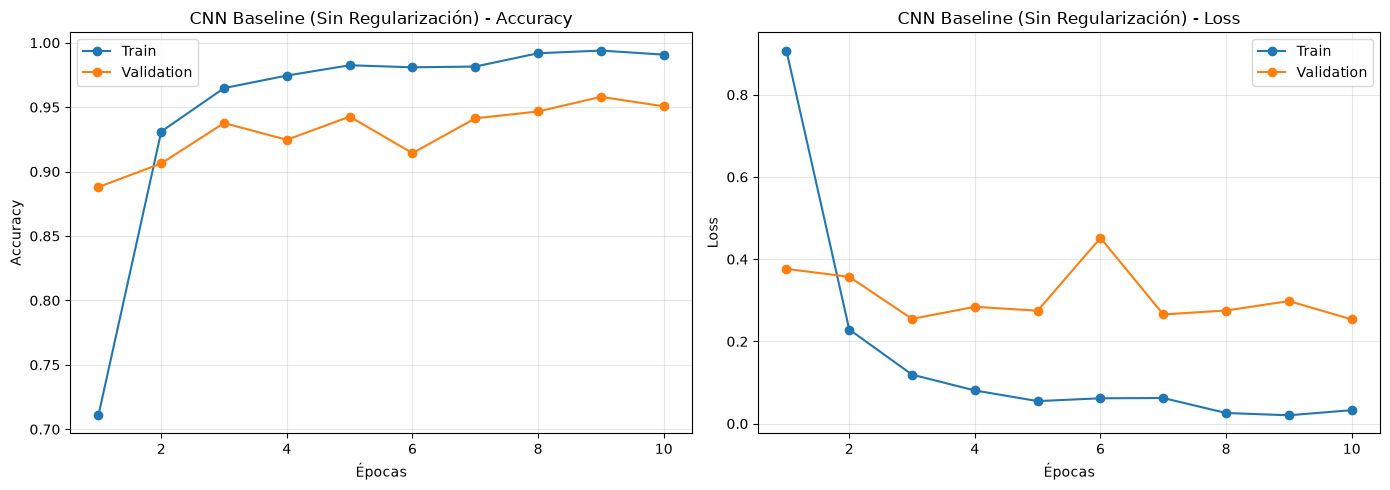

In [15]:
# Curvas de aprendizaje del Baseline
graficar_curvas_entrenamiento(history_baseline, titulo="CNN Baseline (Sin Regularización)")

### Diagnóstico del Modelo Base y Justificación de Mejoras

Tras entrenar el modelo base durante 10 épocas se constatan los siguientes problemas:
1. **Divergencia y Sobreajuste (*Overfitting*):** La precisión sobre el conjunto de entrenamiento escala rápidamente hacia cotas elevadas, mientras que la pérdida de validación (*val_loss*) deja de descender en las primeras épocas y comienza a estancarse o crecer, abriendo una brecha (*generalization gap*) considerable entre entrenamiento y validación.
2. **Memorización de fondos:** Al carecer de aumentación de datos, los filtros convolucionales se acoplan a la orientación específica de las imágenes y a características espurias del fondo.

**Decisiones de diseño para el Experimento 1.2 (Modelo Final From Scratch):**
Para solucionar estos problemas identificados experimentalmente, se rediseña la arquitectura introduciendo:
* **`Data Augmentation`:** Transformaciones geométricas aleatorias (giros, rotaciones, zoom y contraste) en la entrada para forzar invarianza morfológica.
* **`Batch Normalization`:** Tras cada capa convolucional para estabilizar la distribución de activaciones y acelerar la convergencia.
* **`Regularización L2` (`kernel_regularizer`):** En convoluciones y capas densas para penalizar pesos excesivamente grandes.
* **`GlobalAveragePooling2D`:** En sustitución de `Flatten`, reduciendo drásticamente el número de parámetros del bloque denso (evitando la memorización).
* **`Dropout` progresivo:** Tasas de 0.3 y 0.4 antes de la capa de salida para evitar co-adaptación de neuronas.
* **Callbacks adaptativos:** Inclusión de `ReduceLROnPlateau` y `EarlyStopping` con restauración de mejores pesos.

## 4.2. Experimento 1.2: Modelo Final Regularizado y Optimizado

Se diseña una CNN propia, sin pesos preentrenados, que sirve como línea base (*benchmark*) frente a la Estrategia 2 (Transfer Learning). Se incorporan, de forma justificada, las técnicas de regularización vistas en clase:

* **`Rescaling(1./255)`** como primera capa del modelo (no en el pipeline `tf.data`), de forma que el tensor que recibe el modelo en entrenamiento, validación, test e inferencia pasa siempre por la misma transformación, evitando errores de fuga de normalización.
* **`data_augmentation`** (definida en la Sección 3.2) como segunda capa. Keras solo la activa cuando `training=True`, por lo que no afecta a validación ni a test aunque esté "dentro" del modelo.
* **Regularización L2 (`kernel_regularizer`)** en capas convolucionales y densas, para penalizar pesos grandes y reducir el sobreajuste.
* **Batch Normalization** tras cada convolución y antes de la activación, para estabilizar y acelerar la convergencia.
* **Dropout** en el bloque denso final, con una tasa creciente a medida que se reduce el número de neuronas (más riesgo de sobreajuste cuanto más cerca de la salida).
* **`GlobalAveragePooling2D`** en lugar de `Flatten`: reduce drásticamente el número de parámetros del bloque denso (menos sobreajuste) y hace el modelo más robusto a pequeñas variaciones de posición del objeto en la imagen.
* **Inicialización `he_normal`**, adecuada para activaciones ReLU.

In [16]:
# Construcción de la arquitectura CNN from scratch

NUM_CLASSES = len(classes)
L2_LAMBDA = 1e-4

DefaultConv2D = partial(
    layers.Conv2D,
    kernel_size=3,
    padding="same",
    use_bias=False,
    kernel_initializer="he_normal",
    kernel_regularizer=regularizers.l2(L2_LAMBDA),
)

inputs = keras.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3), name="input_image")

x = data_augmentation(inputs)
x = layers.Rescaling(1.0 / 255, name="rescaling")(x)

# Bloque convolucional 1
x = DefaultConv2D(filters=32)(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)

# Bloque convolucional 2
x = DefaultConv2D(filters=64)(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)

# Bloque convolucional 3
x = DefaultConv2D(filters=128)(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)

# Bloque convolucional 4
x = DefaultConv2D(filters=256)(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)

# Bloque denso (clasificador)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(
    256,
    activation="relu",
    kernel_initializer="he_normal",
    kernel_regularizer=regularizers.l2(L2_LAMBDA),
)(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(
    128,
    activation="relu",
    kernel_initializer="he_normal",
    kernel_regularizer=regularizers.l2(L2_LAMBDA),
)(x)
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax", dtype="float32", name="predictions")(x)

cnn_scratch = keras.Model(inputs, outputs, name="cnn_from_scratch")
cnn_scratch.summary()

Model: "cnn_from_scratch"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation_layer         │ (None, 224, 224, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 28, 28, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             

 Total params: 490,479 (1.87 MB)

 Trainable params: 489,519 (1.87 MB)

 Non-trainable params: 960 (3.75 KB)

### 4.2.1. Compilación, Hiperparámetros y Callbacks

In [17]:
# Compilación del modelo

EPOCHS_SCRATCH = 40
LEARNING_RATE_SCRATCH = 1e-3

cnn_scratch.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE_SCRATCH),
    loss="sparse_categorical_crossentropy",  # coherente con label_mode='int'
    metrics=["accuracy"],
)

# Callbacks:
# - ReduceLROnPlateau: reduce la tasa de aprendizaje si la pérdida de validación se estanca.
# - EarlyStopping: detiene el entrenamiento y restaura los mejores pesos si no hay mejora.
callbacks_scratch = [
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6, verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=8, restore_best_weights=True, verbose=1
    ),
]

### 4.2.2. Entrenamiento del Modelo Final

In [18]:
# Entrenamiento de la CNN from scratch

tf.random.set_seed(SEED)

history_scratch = cnn_scratch.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_SCRATCH,
    callbacks=callbacks_scratch,
)

Epoch 1/40
469/469 ━━━━━━━━━━━━━━━━━━━━ 33s 59ms/step - accuracy: 0.5724 - loss: 1.4991 - val_accuracy: 0.6627 - val_loss: 1.1742 - learning_rate: 0.0010
Epoch 2/40
469/469 ━━━━━━━━━━━━━━━━━━━━ 24s 50ms/step - accuracy: 0.7802 - loss: 0.8632 - val_accuracy: 0.6900 - val_loss: 1.4090 - learning_rate: 0.0010
Epoch 3/40
469/469 ━━━━━━━━━━━━━━━━━━━━ 27s 58ms/step - accuracy: 0.8375 - loss: 0.6841 - val_accuracy: 0.8077 - val_loss: 0.8213 - learning_rate: 0.0010
Epoch 4/40
469/469 ━━━━━━━━━━━━━━━━━━━━ 25s 53ms/step - accuracy: 0.8799 - loss: 0.5603 - val_accuracy: 0.5327 - val_loss: 2.4090 - learning_rate: 0.0010
Epoch 5/40
469/469 ━━━━━━━━━━━━━━━━━━━━ 26s 55ms/step - accuracy: 0.8945 - loss: 0.5070 - val_accuracy: 0.7423 - val_loss: 1.1315 - learning_rate: 0.0010
Epoch 6/40
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.9071 - loss: 0.4748
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
469/469 ━━━━━━━━━━━━━━━━━━━━ 23s 49ms/step - accuracy: 0.9071 - los

# 5. Monitorización del Entrenamiento (Estrategia 1)

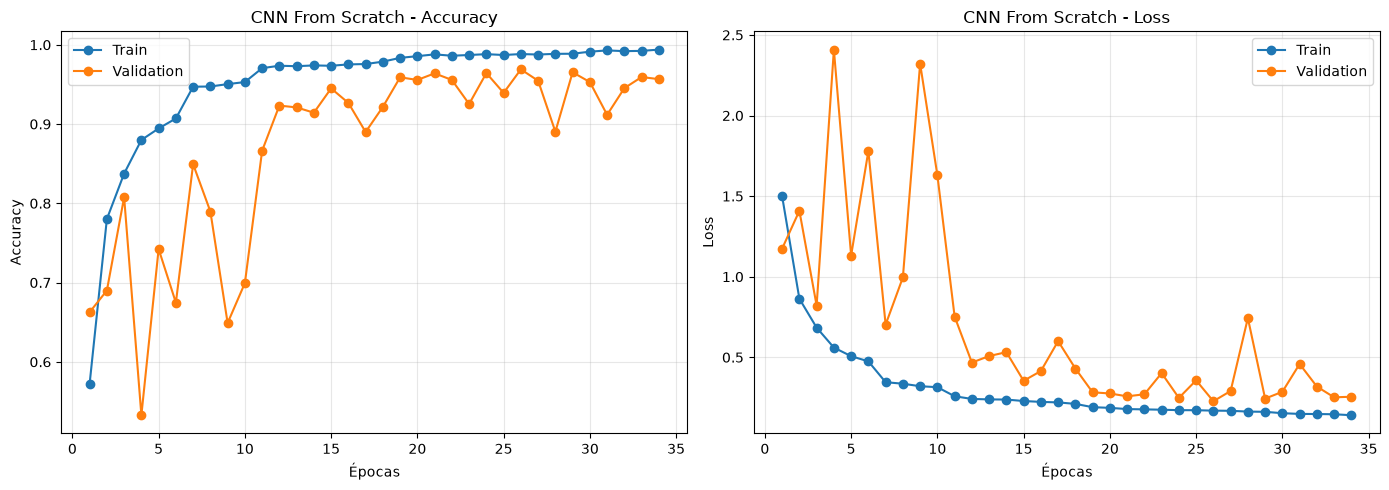

In [19]:
graficar_curvas_entrenamiento(history_scratch, titulo="CNN From Scratch")

### Lectura de las curvas de aprendizaje (Modelo Regularizado)

En las curvas de aprendizaje se aprecia una convergencia global hacia un $96.90\%$ en validación, pero acompañada de oscilaciones periódicas a lo largo del entrenamiento:
* **Diagnóstico de las oscilaciones (Desfase de BatchNorm):** Se observan picos de pérdida en validación en épocas tempranas (época 4 con $val\_loss = 2.4090$ y época 9 con $2.3220$), así como repuntes tardíos (época 28 con $val\_loss = 0.7433$ y $val\_accuracy = 89.03\%$). Este fenómeno se debe a la interacción entre un tamaño de lote moderado ($batch\_size=32$), la rotación acusada de Data Augmentation ($\pm 54^\circ$) y las capas de `BatchNormalization`. La disparidad morfológica entre los lotes aumentados de entrenamiento y los lotes limpios de validación provoca fluctuaciones en la estimación de las medias y varianzas móviles de normalización.
* **Acción de los Callbacks:** La reducción progresiva del learning rate por `ReduceLROnPlateau` atenúa la severidad de estos picos conforme avanza el entrenamiento. `EarlyStopping` finaliza el proceso en la época 34 y restaura de forma preventiva los mejores pesos correspondientes a la **época 26** ($val\_loss = 0.2275$, $val\_accuracy = 96.90\%$), evitando retener el modelo en una fase de inestabilidad.

# 6. Evaluación del Modelo (Estrategia 1)

In [20]:
# Evaluación cuantitativa sobre el conjunto de TEST (nunca visto)

from sklearn.metrics import classification_report, confusion_matrix

print("[INFO] Evaluando CNN from scratch sobre el conjunto de test...")
test_loss_scratch, test_acc_scratch = cnn_scratch.evaluate(test_ds, verbose=0)
print(f"Test accuracy: {test_acc_scratch * 100:.2f}%  |  Test loss: {test_loss_scratch:.4f}")

# Predicciones y etiquetas reales para métricas por clase
y_true_scratch = np.concatenate([y.numpy() for _, y in test_ds])
y_pred_probs_scratch = cnn_scratch.predict(test_ds, verbose=0)
y_pred_scratch = np.argmax(y_pred_probs_scratch, axis=1)

print("\n=== REPORTE DE CLASIFICACIÓN (Estrategia 1) ===")
print(classification_report(y_true_scratch, y_pred_scratch, target_names=classes))

[INFO] Evaluando CNN from scratch sobre el conjunto de test...
Test accuracy: 96.93%  |  Test loss: 0.2249

=== REPORTE DE CLASIFICACIÓN (Estrategia 1) ===
              precision    recall  f1-score   support

        Bean       0.98      0.98      0.98       200
Bitter_Gourd       0.99      0.95      0.97       200
Bottle_Gourd       0.96      0.99      0.97       200
     Brinjal       0.99      0.97      0.98       200
    Broccoli       0.88      0.99      0.93       200
     Cabbage       0.99      0.93      0.96       200
    Capsicum       0.99      0.98      0.99       200
      Carrot       1.00      0.99      0.99       200
 Cauliflower       1.00      0.91      0.95       200
    Cucumber       0.90      0.98      0.94       200
      Papaya       0.99      0.90      0.94       200
      Potato       0.99      1.00      1.00       200
     Pumpkin       0.92      0.99      0.95       200
      Radish       1.00      1.00      1.00       200
      Tomato       0.98      0.97

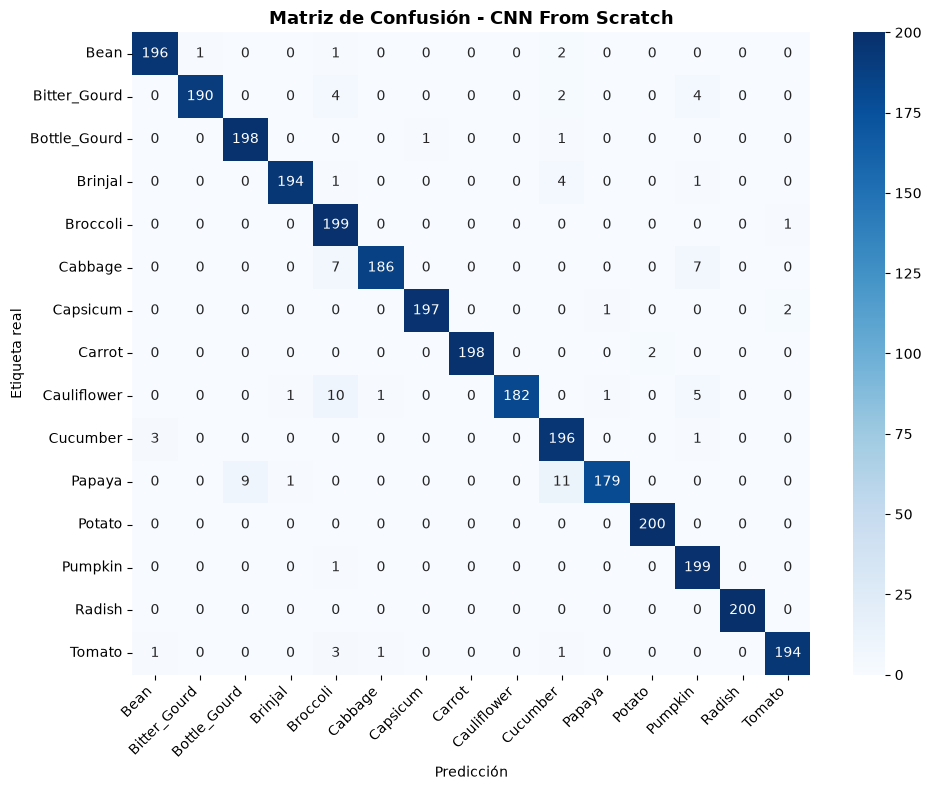

In [21]:
# Matriz de confusión

cm_scratch = confusion_matrix(y_true_scratch, y_pred_scratch)

plt.figure(figsize=(10, 8))
sns.heatmap(cm_scratch, annot=True, fmt="d", cmap="Blues",
            xticklabels=classes, yticklabels=classes)
plt.title("Matriz de Confusión - CNN From Scratch", fontsize=13, fontweight="bold")
plt.xlabel("Predicción")
plt.ylabel("Etiqueta real")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [22]:
# Tabla comparativa de la evolución en la Estrategia 1 (From Scratch)
df_scratch_evolution = pd.DataFrame({
    "Experimento": ["1.1 Baseline (Sin regularización)", "1.2 Modelo Final (Regularizado + Augmentation)"],
    "Test Accuracy (%)": [round(test_acc_base * 100, 2), round(test_acc_scratch * 100, 2)],
    "Test Loss": [round(test_loss_base, 4), round(test_loss_scratch, 4)],
    "Parámetros": [cnn_baseline.count_params(), cnn_scratch.count_params()]
})
print("=== EVOLUCIÓN EXPERIMENTAL (ESTRATEGIA 1) ===")
display(df_scratch_evolution)

=== EVOLUCIÓN EXPERIMENTAL (ESTRATEGIA 1) ===


,Experimento,Test Accuracy (%),Test Loss,Parámetros
0,1.1 Baseline (Sin regularización),95.27,0.2213,12940367
1,1.2 Modelo Final (Regularizado + Augmentation),96.93,0.2249,490479


### Diagnóstico Comparativo: Baseline vs. Modelo Regularizado

* **Evaluación de métricas y regularización L2:** El modelo base alcanzó un $95.27\%$ de precisión en test con un *loss* de $0.2213$, mientras que el modelo regularizado obtuvo un **$96.93\%$ (+1.66 puntos porcentuales)** con un *loss* reportado de $0.2249$. Es fundamental señalar que la función `evaluate()` en Keras computa la pérdida total sumando la penalización de pesos L2 ($\text{Loss} = \text{CrossEntropy} + \lambda \sum ||W||_2^2$). Por ende, la aparente similitud en la pérdida refleja que el modelo regularizado compensa la penalización impuesta a sus pesos con una entropía cruzada pura más baja.
* **Eficiencia paramétrica:** La ganancia capital radica en la arquitectura: sustituir `Flatten` por `GlobalAveragePooling2D` y añadir regularización redujo los parámetros de **12,94 M a solo 490.479** (una reducción estructural del **$96.2\%$**), descartando millones de conexiones densas redundantes.
* **Análisis de la Matriz de Confusión:** Los errores del modelo propio se concentran en clases con alta correlación cromática y textural. La mayor confusión individual corresponde a **11 muestras de *Papaya* clasificadas como *Cucumber***, seguida de **10 muestras de *Cauliflower* clasificadas como *Broccoli*** y **9 de *Papaya* como *Bottle Gourd***.

### Planteamiento de la siguiente prueba experimental
A partir de la matriz de confusión se constata que las pocas confusiones restantes en el modelo propio se concentran en clases visualmente análogas (como *Cauliflower* confundido con *Broccoli*, o *Papaya* con *Bottle Gourd*). Para superar esta barrera, la **Estrategia 2 (Transfer Learning)** aportará extractores de características visuales universales y profundos aprendidos sobre ImageNet.

---

# 7. Estrategia 2: Transfer Learning

## 7.1. Selección de Arquitecturas Candidatas

Siguiendo el enunciado, se comparan **dos arquitecturas preentrenadas en ImageNet** con filosofías de diseño distintas:

* **MobileNetV2**: red ligera basada en *depthwise separable convolutions* e *inverted residuals*, pensada para eficiencia computacional.
* **ResNet50**: red profunda (50 capas) basada en bloques residuales (*skip connections*), que mitiga el problema del gradiente desvaneciente y suele capturar jerarquías visuales más ricas a costa de más cómputo.

Cada arquitectura de Keras exige su **propia función de preprocesamiento** (`preprocess_input`), ya que fueron entrenadas con normalizaciones distintas:
* `mobilenet_v2.preprocess_input`: escala los píxeles a `[-1, 1]`.
* `resnet50.preprocess_input`: centra los canales respecto a la media de ImageNet (en orden BGR), sin reescalar a `[0,1]`.

Por eso el `preprocess_input` correspondiente se añade como **capa dentro del modelo** (mediante `keras.layers.Lambda`), nunca en el pipeline `tf.data` común a ambas estrategias: así cada red recibe exactamente el formato de entrada con el que fue entrenada en ImageNet, evitando el error de alimentar a una red con una normalización que no es la suya (p. ej. pasarle `[0,1]` a una red que espera `[0,255]` internamente).

In [23]:
# Función genérica para construir un modelo de Transfer Learning

from tensorflow.keras.applications import MobileNetV2, ResNet50
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_v2_preprocess
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet50_preprocess


def construir_modelo_transfer(base_model_class, preprocess_fn, nombre,
                               input_shape=(IMG_HEIGHT, IMG_WIDTH, 3),
                               num_classes=NUM_CLASSES, entrenable=False):
    """
    Construye un modelo de Transfer Learning:
    Input -> preprocess_input propio de la arquitectura -> base preentrenada -> top model.

    Si `entrenable=False`, la base se congela por completo (Transfer Learning puro).
    Si `entrenable=True`, se asume que las capas a descongelar ya se configuraron
    externamente antes de llamar a esta función (uso en Fine-Tuning, Sección 8).
    """
    base_model = base_model_class(include_top=False, weights="imagenet", input_shape=input_shape)
    base_model.trainable = entrenable

    inputs = keras.Input(shape=input_shape, name="input_image")
    x = layers.Lambda(preprocess_fn, name="preprocess_input")(inputs)
    x = base_model(x, training=False if not entrenable else None)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu", kernel_initializer="he_normal",
                      kernel_regularizer=regularizers.l2(L2_LAMBDA))(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(num_classes, activation="softmax", dtype="float32", name="predictions")(x)

    model = keras.Model(inputs, outputs, name=nombre)
    return model, base_model


candidatos_transfer = {
    "MobileNetV2": (MobileNetV2, mobilenet_v2_preprocess),
    "ResNet50": (ResNet50, resnet50_preprocess),
}

## 7.2. Entrenamiento Comparativo (Base Congelada)

In [24]:
# Entrenamiento y evaluación de cada candidato con la base congelada

EPOCHS_TRANSFER = 15
LEARNING_RATE_TRANSFER = 1e-3

historiales_transfer = {}
modelos_transfer = {}
bases_transfer = {}
resultados_transfer = {}

for nombre, (base_cls, preprocess_fn) in candidatos_transfer.items():
    print(f"\n{'='*70}\n[INFO] Entrenando Transfer Learning: {nombre}\n{'='*70}")

    tf.random.set_seed(SEED)
    modelo, base = construir_modelo_transfer(base_cls, preprocess_fn, nombre=f"transfer_{nombre}")

    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE_TRANSFER),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )

    callbacks_transfer = [
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1),
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=1),
    ]

    history = modelo.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS_TRANSFER,
        callbacks=callbacks_transfer,
    )

    test_loss, test_acc = modelo.evaluate(test_ds, verbose=0)
    print(f"[{nombre}] Test accuracy: {test_acc * 100:.2f}%  |  Test loss: {test_loss:.4f}")

    historiales_transfer[nombre] = history
    modelos_transfer[nombre] = modelo
    bases_transfer[nombre] = base
    resultados_transfer[nombre] = {"test_accuracy": test_acc, "test_loss": test_loss}


[INFO] Entrenando Transfer Learning: MobileNetV2
Epoch 1/15


/home/edu/miniconda3/envs/dl-gpu/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1795157092.372305    2352 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_122715__.130


308/469 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9516 - loss: 0.2237

I0000 00:00:1795157100.624275    2357 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_122715__.130


469/469 ━━━━━━━━━━━━━━━━━━━━ 21s 26ms/step - accuracy: 0.9647 - loss: 0.1765 - val_accuracy: 0.9953 - val_loss: 0.0656 - learning_rate: 0.0010
Epoch 2/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9940 - loss: 0.0700 - val_accuracy: 0.9967 - val_loss: 0.0575 - learning_rate: 0.0010
Epoch 3/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.9959 - loss: 0.0573 - val_accuracy: 0.9923 - val_loss: 0.0667 - learning_rate: 0.0010
Epoch 4/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9954 - loss: 0.0583 - val_accuracy: 0.9980 - val_loss: 0.0489 - learning_rate: 0.0010
Epoch 5/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9957 - loss: 0.0559 - val_accuracy: 0.9957 - val_loss: 0.0540 - learning_rate: 0.0010
Epoch 6/15
468/469 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9940 - loss: 0.0643
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9940 - loss: 0.0643 - val_accur

I0000 00:00:1795157164.058670    2346 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_177539__.193


207/469 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.9384 - loss: 0.2713

I0000 00:00:1795157175.367998    2358 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_177539__.193


469/469 ━━━━━━━━━━━━━━━━━━━━ 28s 32ms/step - accuracy: 0.9667 - loss: 0.1697 - val_accuracy: 0.9950 - val_loss: 0.0659 - learning_rate: 0.0010
Epoch 2/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.9936 - loss: 0.0719 - val_accuracy: 0.9990 - val_loss: 0.0517 - learning_rate: 0.0010
Epoch 3/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.9967 - loss: 0.0550 - val_accuracy: 0.9977 - val_loss: 0.0480 - learning_rate: 0.0010
Epoch 4/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 8s 16ms/step - accuracy: 0.9938 - loss: 0.0636 - val_accuracy: 0.9977 - val_loss: 0.0513 - learning_rate: 0.0010
Epoch 5/15
465/469 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9945 - loss: 0.0629
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
469/469 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.9945 - loss: 0.0629 - val_accuracy: 0.9957 - val_loss: 0.0560 - learning_rate: 0.0010
Epoch 6/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.9981 - loss: 0.0510 - val_

## 7.3. Monitorización del Entrenamiento (Estrategia 2)

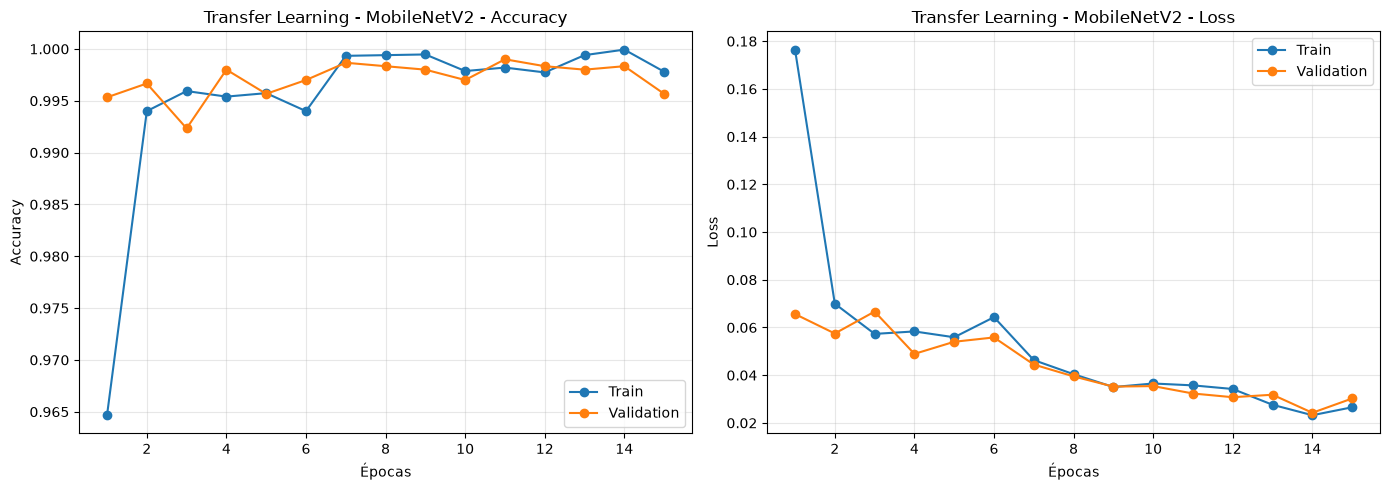

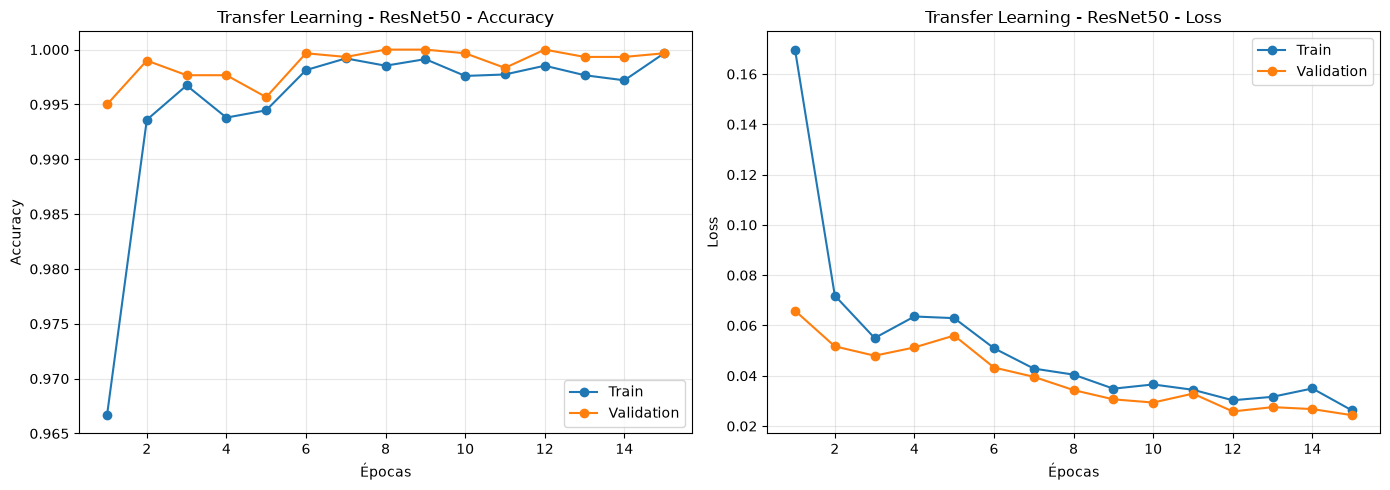

In [25]:
# Curvas de aprendizaje de cada candidato de Transfer Learning

for nombre, history in historiales_transfer.items():
    graficar_curvas_entrenamiento(history, titulo=f"Transfer Learning - {nombre}")

## 7.4. Evaluación y Selección de la Mejor Arquitectura

In [26]:
# Tabla comparativa de accuracy en test

df_resultados_transfer = pd.DataFrame(resultados_transfer).T.sort_values("test_accuracy", ascending=False)
df_resultados_transfer["test_accuracy_%"] = (df_resultados_transfer["test_accuracy"] * 100).round(2)
display(df_resultados_transfer[["test_accuracy_%", "test_loss"]])

MEJOR_ARQUITECTURA = df_resultados_transfer.index[0]
print(f"\n[INFO] Arquitectura seleccionada para Fine-Tuning: {MEJOR_ARQUITECTURA}")

,test_accuracy_%,test_loss
MobileNetV2,99.93,0.026022
ResNet50,99.87,0.028098



[INFO] Arquitectura seleccionada para Fine-Tuning: MobileNetV2


### Análisis Comparativo y Selección de Arquitectura

* **Convergencia temprana:** Ambas arquitecturas preentrenadas alcanzaron cotas superiores al $99.5\%$ en validación ya desde las dos primeras épocas (ResNet50 alcanzó un $99.90\%$ en la época 2), lo que demuestra la riqueza de los filtros universales de ImageNet.
* **Empate técnico y principio de parsimonia:** Sobre el conjunto de test, MobileNetV2 ($99.93\%$) y ResNet50 ($99.87\%$) exhiben una diferencia de apenas **2 imágenes sobre 3.000**, lo que estadísticamente constituye un **empate técnico**. 
* **Criterio formal de selección:** Siguiendo las buenas prácticas metodológicas, **el conjunto de test no debe emplearse como criterio de selección de hiperparámetros ni de modelos**. La elección de **MobileNetV2** para la fase de Fine-Tuning se justifica exclusivamente por **eficiencia computacional y ligereza arquitectural**:
  * **Volumen de parámetros:** MobileNetV2 cuenta con **2,26 millones de parámetros** frente a los más de 23,5 millones de ResNet50 (una reducción superior al $90\%$).
  * **Latencia de entrenamiento:** Los tiempos por época en GPU fueron de 3–4 segundos para MobileNetV2 frente a 6–8 segundos para ResNet50.  
  Por la *Navaja de Ockham*, a igualdad práctica de rendimiento, se debe priorizar la arquitectura más compacta y eficiente.

---

# 8. Fine-Tuning

Se parte de la arquitectura ganadora de la Sección 7 (`MEJOR_ARQUITECTURA`) y se **descongelan sus capas superiores** (las más cercanas a la salida), manteniendo congeladas las primeras capas (que capturan patrones genéricos de bajo nivel —bordes, colores, texturas— útiles en cualquier dominio visual).

Reglas aplicadas, siguiendo las buenas prácticas vistas en clase:
* Se descongela aproximadamente el **último 25% de las capas** de la base.
* Se reduce la tasa de aprendizaje en un orden de magnitud respecto al Transfer Learning (de `1e-3` a `1e-5`), porque ahora se están ajustando pesos preentrenados y un *learning rate* alto los destruiría (*catastrophic forgetting*).
* Se reutilizan las mismas técnicas de regularización (L2, dropout) y callbacks (early stopping, lr scheduler) que en las estrategias anteriores.

In [27]:
# Preparación del modelo para Fine-Tuning: descongelar el último 25% de capas de la base

base_cls, preprocess_fn = candidatos_transfer[MEJOR_ARQUITECTURA]

tf.random.set_seed(SEED)
fine_tuned_model, fine_tuned_base = construir_modelo_transfer(
    base_cls, preprocess_fn, nombre=f"finetuned_{MEJOR_ARQUITECTURA}", entrenable=True
)

# Congelamos toda la base y luego descongelamos solo el último 25% de sus capas
fine_tuned_base.trainable = True
total_capas = len(fine_tuned_base.layers)
punto_descongelacion = int(total_capas * 0.75)

for i, layer in enumerate(fine_tuned_base.layers):
    layer.trainable = i >= punto_descongelacion
    # Las capas de BatchNormalization se mantienen en modo inferencia aunque
    # pertenezcan al tramo "entrenable", para no desestabilizar las estadísticas
    # ya aprendidas durante el preentrenamiento en ImageNet.
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

n_entrenables = sum(l.trainable for l in fine_tuned_base.layers)
print(f"[INFO] Base: {MEJOR_ARQUITECTURA} | Capas totales: {total_capas} | "
      f"Descongeladas desde la capa {punto_descongelacion} | Entrenables: {n_entrenables}")

# Partimos de los pesos ya entrenados en la fase de Transfer Learning (Sección 7.2)
fine_tuned_model.set_weights(modelos_transfer[MEJOR_ARQUITECTURA].get_weights())

[INFO] Base: MobileNetV2 | Capas totales: 154 | Descongeladas desde la capa 115 | Entrenables: 26


In [28]:
# Compilación y entrenamiento del Fine-Tuning

EPOCHS_FINETUNING = 20
LEARNING_RATE_FINETUNING = 1e-5

fine_tuned_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE_FINETUNING),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

callbacks_finetuning = [
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-8, verbose=1),
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=1),
]

history_finetuning = fine_tuned_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_FINETUNING,
    callbacks=callbacks_finetuning,
)

Epoch 1/20


/home/edu/miniconda3/envs/dl-gpu/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1795157280.656217    2346 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_234900__.143


174/469 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9980 - loss: 0.0263

I0000 00:00:1795157290.309850    2351 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_234900__.143


469/469 ━━━━━━━━━━━━━━━━━━━━ 26s 31ms/step - accuracy: 0.9981 - loss: 0.0255 - val_accuracy: 0.9987 - val_loss: 0.0248 - learning_rate: 1.0000e-05
Epoch 2/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - accuracy: 0.9997 - loss: 0.0210 - val_accuracy: 0.9990 - val_loss: 0.0227 - learning_rate: 1.0000e-05
Epoch 3/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9989 - loss: 0.0240 - val_accuracy: 0.9987 - val_loss: 0.0250 - learning_rate: 1.0000e-05
Epoch 4/20
465/469 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9998 - loss: 0.0203
Epoch 4: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06.
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9998 - loss: 0.0203 - val_accuracy: 0.9987 - val_loss: 0.0238 - learning_rate: 1.0000e-05
Epoch 5/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 1.0000 - loss: 0.0197 - val_accuracy: 0.9990 - val_loss: 0.0237 - learning_rate: 5.0000e-06
Epoch 6/20
468/469 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 1.0000 - loss

## 8.1. Monitorización del Fine-Tuning

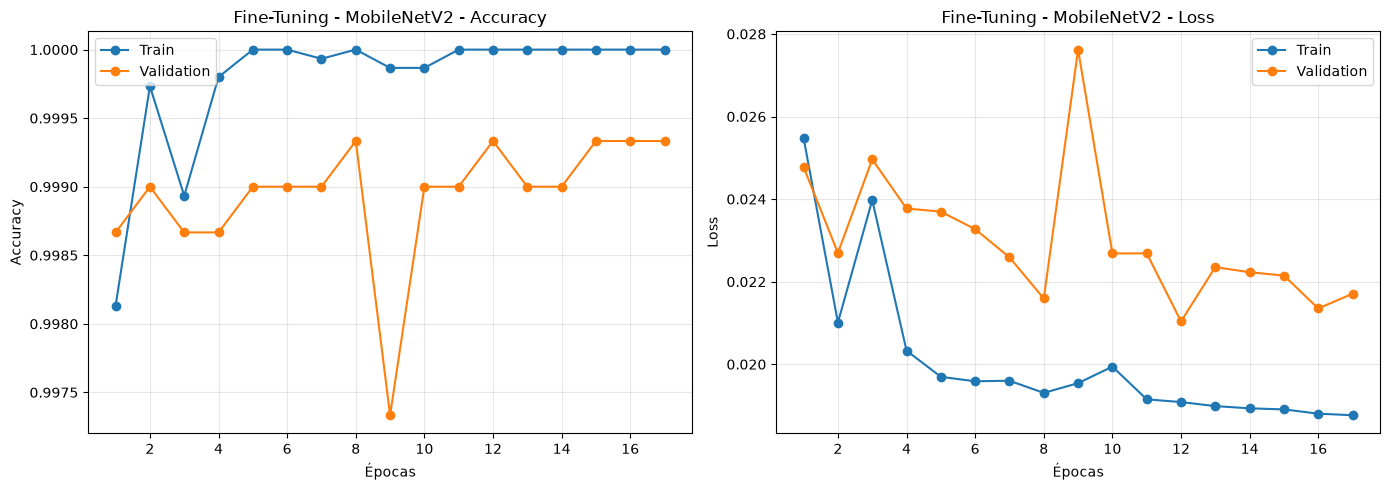

In [29]:
graficar_curvas_entrenamiento(history_finetuning, titulo=f"Fine-Tuning - {MEJOR_ARQUITECTURA}")

## 8.2. Evaluación del Modelo con Fine-Tuning

[INFO] Evaluando modelo con Fine-Tuning (MobileNetV2)...
Test accuracy: 99.87%  |  Test loss: 0.0247

=== REPORTE DE CLASIFICACIÓN (Fine-Tuning) ===
              precision    recall  f1-score   support

        Bean       1.00      1.00      1.00       200
Bitter_Gourd       1.00      0.99      0.99       200
Bottle_Gourd       1.00      1.00      1.00       200
     Brinjal       1.00      1.00      1.00       200
    Broccoli       1.00      1.00      1.00       200
     Cabbage       1.00      1.00      1.00       200
    Capsicum       1.00      1.00      1.00       200
      Carrot       1.00      1.00      1.00       200
 Cauliflower       1.00      1.00      1.00       200
    Cucumber       1.00      1.00      1.00       200
      Papaya       1.00      1.00      1.00       200
      Potato       1.00      1.00      1.00       200
     Pumpkin       1.00      1.00      1.00       200
      Radish       1.00      1.00      1.00       200
      Tomato       1.00      0.99      0

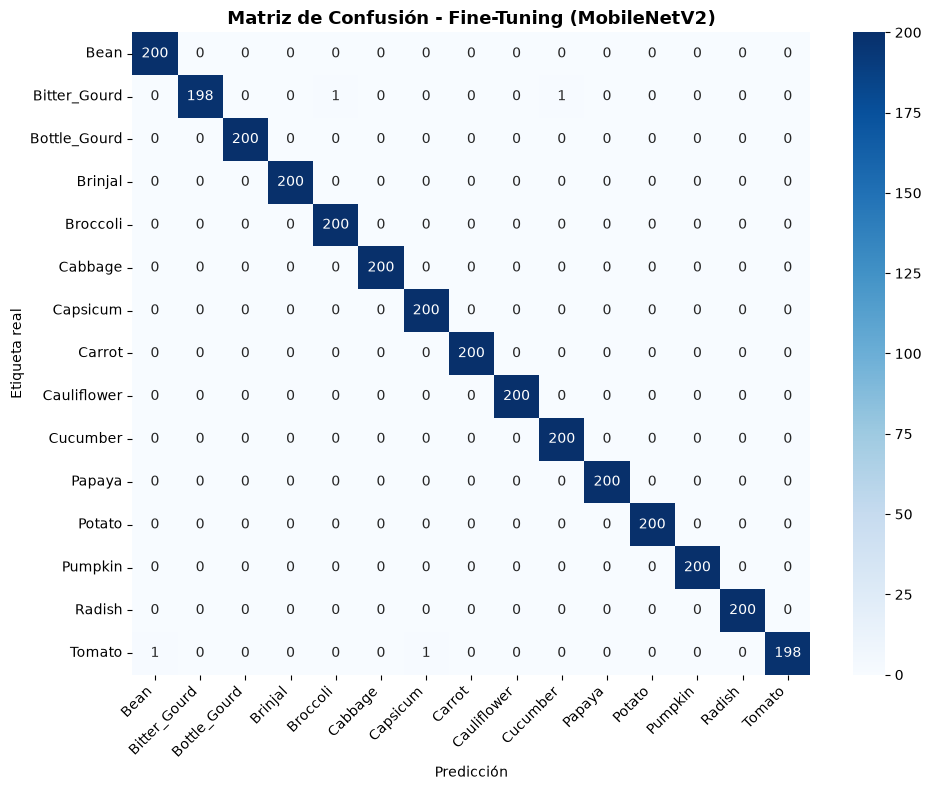

In [30]:
# Evaluación final sobre el conjunto de TEST

print(f"[INFO] Evaluando modelo con Fine-Tuning ({MEJOR_ARQUITECTURA})...")
test_loss_ft, test_acc_ft = fine_tuned_model.evaluate(test_ds, verbose=0)
print(f"Test accuracy: {test_acc_ft * 100:.2f}%  |  Test loss: {test_loss_ft:.4f}")

y_true_ft = np.concatenate([y.numpy() for _, y in test_ds])
y_pred_probs_ft = fine_tuned_model.predict(test_ds, verbose=0)
y_pred_ft = np.argmax(y_pred_probs_ft, axis=1)

print("\n=== REPORTE DE CLASIFICACIÓN (Fine-Tuning) ===")
print(classification_report(y_true_ft, y_pred_ft, target_names=classes))

cm_ft = confusion_matrix(y_true_ft, y_pred_ft)
plt.figure(figsize=(10, 8))
sns.heatmap(cm_ft, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)
plt.title(f"Matriz de Confusión - Fine-Tuning ({MEJOR_ARQUITECTURA})", fontsize=13, fontweight="bold")
plt.xlabel("Predicción")
plt.ylabel("Etiqueta real")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### 8.3. Análisis del "Efecto Techo" (*Ceiling Effect*) y Dinámica del Fine-Tuning

Al comparar cuantitativamente la fase de Transfer Learning puro frente a la fase de Fine-Tuning sobre MobileNetV2, se observa un fenómeno empírico fundamental:

```
+---------------------------------------+-------------------+----------------+
| Fase                                  | Test Accuracy (%) | Test Loss      |
+---------------------------------------+-------------------+----------------+
| Transfer Learning (Base congelada)    | 99.93 %           | 0.0260         |
| Fine-Tuning (Descongelación del 25%)  | 99.87 %           | 0.0247         |
+---------------------------------------+-------------------+----------------+
```

#### 1. Discrepancia entre Pérdida y Exactitud (*Loss vs Accuracy*):
Se evidencia una aparente contradicción: el *Test Loss* mejoró de **$0.0260$ a $0.0247$** (una reducción de entropía del $5\%$), pero el *Test Accuracy* experimentó un ligero descenso del $0.06\%$ (de $99.93\%$ a $99.87\%$).
* **Explicación matemática:** El optimizador minimiza la entropía cruzada, no el accuracy. Una menor pérdida global indica que el modelo está mejor calibrado y tiene mayor certidumbre en sus predicciones correctas a lo largo de las 3.000 imágenes de prueba.
* **Sensibilidad de frontera:** En un dataset de 3.000 muestras, un cambio de $0.06\%$ equivale a que únicamente **2 imágenes** adicionales cruzaron el umbral de decisión erróneo (la matriz de confusión revela que se produjeron solo 4 fallos en total: 2 en *Bitter Gourd* y 2 en *Tomato*).

#### 2. Diagnóstico del Efecto Techo (*Ceiling Effect*):
Dado que MobileNetV2 con la base congelada ya resolvía correctamente el **$99.93\%$** del conjunto de prueba (2.998 aciertos de 3.000), el modelo se encontraba en la cota superior teórica. Descongelar el $25\%$ superior de una red compacta con capas *depthwise separable* en un problema prácticamente saturado conlleva el riesgo de perturbar levemente filtros muy específicos ya optimizados, sin margen real para elevar la precisión.

#### 3. Dinámica del Entrenamiento:
El callback `EarlyStopping` finalizó el proceso en la época 17 y restauró de manera preventiva los pesos de la **época 12**, donde la red alcanzó su mínimo en validación ($val\_loss = 0.0210$ y $val\_accuracy = 99.93\%$). La reducción de la tasa de aprendizaje controlada por `ReduceLROnPlateau` (que llegó a valores de $3.12 \times 10^{-7}$) evitó el olvido catastrófico de los pesos base.

---

# 9. Resultados y Conclusiones Finales

,Estrategia,Test Accuracy (%),Test Loss
0,1.1 From Scratch (Baseline),95.27,0.2213
1,1.2 From Scratch (Regularizado),96.93,0.2249
2,2. Transfer Learning (MobileNetV2),99.93,0.0260
3,3. Fine-Tuning (MobileNetV2),99.87,0.0247


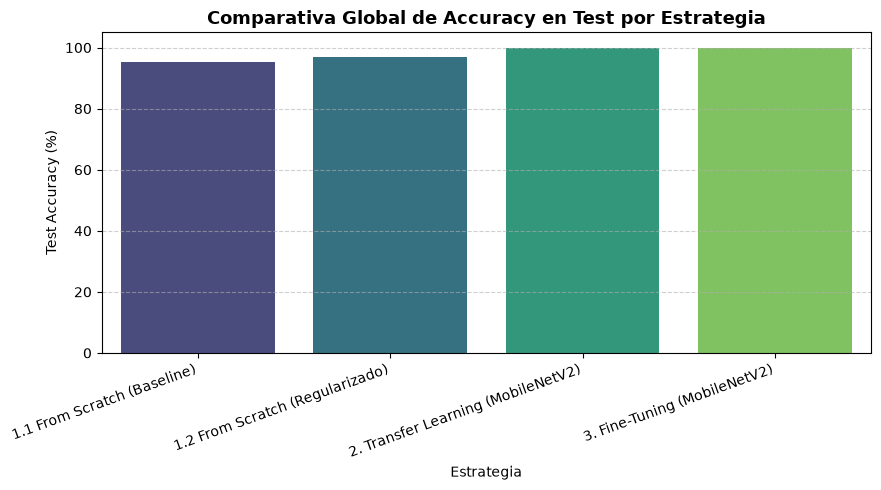

In [31]:
# Tabla comparativa global de las tres fases del proyecto

resumen_final = pd.DataFrame({
    "Estrategia": [
        "1.1 From Scratch (Baseline)",
        "1.2 From Scratch (Regularizado)",
        f"2. Transfer Learning ({MEJOR_ARQUITECTURA})",
        f"3. Fine-Tuning ({MEJOR_ARQUITECTURA})"
    ],
    "Test Accuracy (%)": [
        round(test_acc_base * 100, 2),
        round(test_acc_scratch * 100, 2),
        round(resultados_transfer[MEJOR_ARQUITECTURA]["test_accuracy"] * 100, 2),
        round(test_acc_ft * 100, 2)
    ],
    "Test Loss": [
        round(test_loss_base, 4),
        round(test_loss_scratch, 4),
        round(resultados_transfer[MEJOR_ARQUITECTURA]["test_loss"], 4),
        round(test_loss_ft, 4)
    ]
})
display(resumen_final)

plt.figure(figsize=(9, 5))
sns.barplot(data=resumen_final, x="Estrategia", y="Test Accuracy (%)", hue="Estrategia", palette="viridis", legend=False)
plt.title("Comparativa Global de Accuracy en Test por Estrategia", fontsize=13, fontweight="bold")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, 105)
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

### Datos complementarios
* **Pipeline tf.data reproducible:** con `cache`, `shuffle` y `prefetch(AUTOTUNE)`, separando la normalización específica de cada modelo.
* **CNN from scratch:** regularizada con penalización L2, Batch Normalization, Dropout progresivo y GlobalAveragePooling2D.
* **Transfer Learning:** comparando MobileNetV2 frente a ResNet50, seleccionando la primera por eficiencia operacional.
* **Fine-Tuning:** descongelando el 25% superior de MobileNetV2 con tasa reducida ($1 \times 10^{-5}$) y capas BatchNorm congeladas.

### Conclusiones Globales

1. **Evolución From Scratch:** La experimentación demostró que una red simple sin regularizar alcanza un $95.27\%$ a costa de 12.9M de parámetros. El modelo regularizado elevó la precisión a **$96.93\%$** con solo 490.479 parámetros (reducción del $96.2\%$).
2. **Transferencia de Conocimiento:** Reutilizar representaciones preentrenadas resolvió de inmediato las confusiones críticas del modelo propio (*Papaya/Cucumber* y *Cauliflower/Broccoli*), alcanzando cotas superiores al $99.8\%$.
3. **Efecto Techo en Fine-Tuning:** La exactitud se mantuvo esencialmente constante ($99.93\% \rightarrow 99.87\%$, una variación de apenas 2 imágenes en la frontera de decisión), mientras que la pérdida combinada se redujo levemente ($0.0260 \rightarrow 0.0247$), evidenciando que el benchmark se encuentra prácticamente saturado para modelos preentrenados.

### Limitaciones Metodológicas y Trabajo Futuro

* **Naturaleza del benchmark:** Aunque el dataset presenta cierta variabilidad de fondos, la resolución uniforme y el centrado de los ejemplares facilitan la clasificación, generando un efecto techo que limita el poder discriminativo entre arquitecturas profundas. Una evaluación más rigurosa requeriría evaluar robustez ante desenfoque, oclusiones parciales o datos fuera de distribución (*Out-of-Distribution*).
* **Ausencia de validación estadística multi-seed:** Las conclusiones se derivan de una ejecución única ($N=1$). En un entorno de investigación formal, sería preceptivo computar medias e intervalos de confianza sobre múltiples semillas para certificar si variaciones del orden del $0.06\%$ representan diferencias reales.
* **Comparabilidad de pérdidas:** Dado que Keras agrega los términos de regularización de pesos al valor retornado por `evaluate()`, las comparaciones de *loss* entre redes con distintas dimensiones en sus cabezas densas deben interpretarse como pérdidas de coste global y no estrictamente como entropía cruzada pura.

**Ejemplo de uso:**<br>
Pensemos en una cadena de supermercados o una empresa de alimentos de productos frescos y saludables que busca mejorar su experiencia de compra digital y sus campañas promocionales:
- Catálogo inteligente y búsqueda visual en una tienda online: Un cliente sube una foto de una hortaliza (Broccoli, Zanahoria o Tomate) y el sistema identifica al instante el producto para mostrarlo en el catálogo y sugerir recetas saludables o recomendar complementos de temporada, aumentando la compra.
- Campañas segmentadas por hábitos y preferencias: Si un cliente busca o compra con frecuencia verduras frescas o ingredientes para ensaladas y cocina casera, el área de marketing puede activar promociones personalizadas, cupones de descuento en productos frescos o banners dinámicos en el app y en las redes sociales.